# Step 3: The room's rhythm

If the decline came from people moving from student schedules to working ones, these four
measures should all move the same way.

| | Prediction | Result |
|---|---|---|
| Posting hour | drifts **earlier** | Not supported. Some members drift ~1h **later** (2021–2025 only) |
| Weekend share | **rises** | Not supported. No effect detectable at quarterly resolution |
| Seasonality | academic troughs **fade** | Partly, but tangled up with the football calendar |
| Reply latency | **rises** | In seconds yes; counted in messages, no change |
| *(not predicted)* | — | **Explicit reply share rose 12.5% → 16.0%** |

None of the four predictions is supported. One thing that wasn't predicted did change: the share
of messages sent as explicit replies.

**Time zone:** everything uses `Europe/Bucharest`. The data has no per-member time zone. One
reference zone shifts every year equally, so year-to-year drift is unaffected; absolute hours
like "peaks at 23:00" are Bucharest time.

In [1]:
import re
import os
import warnings
import psycopg2
import pandas as pd

warnings.filterwarnings("ignore", message=".*only supports SQLAlchemy.*")

REPO_ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
SQL_PATH = os.path.join(REPO_ROOT, "sql", "03_corroborating.sql")
TABLES_DIR = os.path.join(REPO_ROOT, "outputs", "tables")
os.makedirs(TABLES_DIR, exist_ok=True)

def load_labeled_queries(path):
    with open(path, encoding="utf-8") as f:
        sql = f.read()
    parts = re.split(r"--\s*QUERY:\s*(\w+)", sql)
    return {name: body.strip().rstrip(";") for name, body in zip(parts[1::2], parts[2::2])}

queries = load_labeled_queries(SQL_PATH)
print(f"Loaded {len(queries)} labeled queries: {list(queries.keys())}")

Loaded 11 labeled queries: ['circadian_hour_year', 'member_median_hour_year', 'weekend_share_year', 'seasonality_month_year', 'reply_latency_year', 'reply_interposed_year', 'weekend_premium_quarter', 'reply_share_year', 'hour_by_month', 'reply_share_month', 'member_year_replies']


In [2]:
try:
    conn = psycopg2.connect(host="localhost", port=5432, dbname="postgres", user="postgres",
                            options="-c timezone=Europe/Bucharest")
except psycopg2.OperationalError:
    conn = None
    print("No database connection: using the saved tables in outputs/tables/.")
if conn is not None:
    for name, sql in queries.items():
        df = pd.read_sql(sql, conn)
        df.to_csv(os.path.join(TABLES_DIR, f"{name}.csv"), index=False)
        print(f"{name}: {len(df)} rows")
    conn.close()

circadian_hour_year: 167 rows


member_median_hour_year: 148 rows


weekend_share_year: 7 rows


seasonality_month_year: 74 rows


reply_latency_year: 6 rows


...

weekend_premium_quarter: 21 rows


reply_share_year: 7 rows


hour_by_month: 12 rows


reply_share_month: 68 rows


member_year_replies: 202 rows


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
CHARTS_DIR = os.path.join(REPO_ROOT, "outputs", "charts")
os.makedirs(CHARTS_DIR, exist_ok=True)

circadian  = pd.read_csv(os.path.join(TABLES_DIR, "circadian_hour_year.csv"))
member_hr  = pd.read_csv(os.path.join(TABLES_DIR, "member_median_hour_year.csv"))
weekend    = pd.read_csv(os.path.join(TABLES_DIR, "weekend_share_year.csv"))
wk_quarter = pd.read_csv(os.path.join(TABLES_DIR, "weekend_premium_quarter.csv"))
seasonal   = pd.read_csv(os.path.join(TABLES_DIR, "seasonality_month_year.csv"))
latency    = pd.read_csv(os.path.join(TABLES_DIR, "reply_latency_year.csv"))
interposed = pd.read_csv(os.path.join(TABLES_DIR, "reply_interposed_year.csv"))
reply_share = pd.read_csv(os.path.join(TABLES_DIR, "reply_share_year.csv"))
hour_month  = pd.read_csv(os.path.join(TABLES_DIR, "hour_by_month.csv"))
reply_month = pd.read_csv(os.path.join(TABLES_DIR, "reply_share_month.csv"))

PRE_COMMUNITY = 2020
PARTIAL_YEAR  = 2026
DAY_START     = 7

def real_years(df, col="year"):
    return df[df[col] > PRE_COMMUNITY]

def to_rot(h):
    return (h - DAY_START) % 24

def from_rot(r):
    return (r + DAY_START) % 24

print("2020 excluded from trends (pre-community); 2026 marked partial.")
print(f"Hours are averaged on a clock starting at {DAY_START:02d}:00 (see section 1).")

2020 excluded from trends (pre-community); 2026 marked partial.
Hours are averaged on a clock starting at 07:00 (see section 1).


## 1. Posting hour

The busiest hour is **23:00 in every year**. The average of members' median posting hours drifts
later, from 20:35 in 2021 to 21:38 in 2025: the opposite of the prediction. That is an average;
individual members moved in both directions:

- Among members present in both years, 2021 → 2025 moves 11 later, 2 earlier and 5 not at all.
- It doesn't last: 2022 → 2026 is 6 later, 7 earlier and 4 unchanged.

It isn't a change in who is posting: leaving out the two members who first posted in 2024 barely changes it
(2024: 21.43 → 21.47; 2025: 21.57 → 21.68).

Hours are averaged on a clock shifted to start at 07:00, the quietest hour, so that 00:30 counts
as later than 23:30 rather than 23 hours earlier. This is an ordinary average on the shifted
clock; it works because almost nobody posts around 07:00, so no member's hours wrap past it.

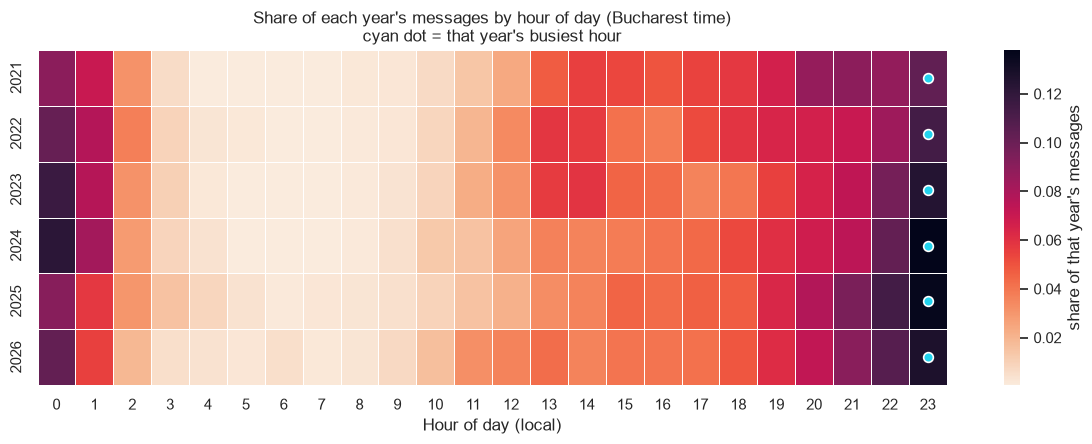

Share of messages posted 00:00-05:59:
  2021  19.9%
  2022  22.9%
  2023  23.7%
  2024  24.7%
  2025  20.7%
  2026  18.9%


In [4]:
piv = real_years(circadian).pivot(index="year", columns="hour", values="share_of_year")

fig, ax = plt.subplots(figsize=(12, 4.6))
sns.heatmap(piv, cmap="rocket_r", ax=ax, cbar_kws={"label": "share of that year's messages"},
            linewidths=0.4, linecolor="white")
for i, (y, row) in enumerate(piv.iterrows()):
    ax.plot(row.values.argmax() + 0.5, i + 0.5, marker="o", markersize=7,
            color="#22d3ee", markeredgecolor="white", markeredgewidth=1.2)
ax.set_title("Share of each year's messages by hour of day (Bucharest time)\n"
             "cyan dot = that year's busiest hour",
             fontsize=12)
ax.set_xlabel("Hour of day (local)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "10_circadian_heatmap.png"), dpi=150)
plt.show()

late = real_years(circadian)
late = late[late["hour"] <= 5].groupby("year")["share_of_year"].sum()
print("Share of messages posted 00:00-05:59:")
for y, v in late.items():
    print(f"  {y}  {v:.1%}")

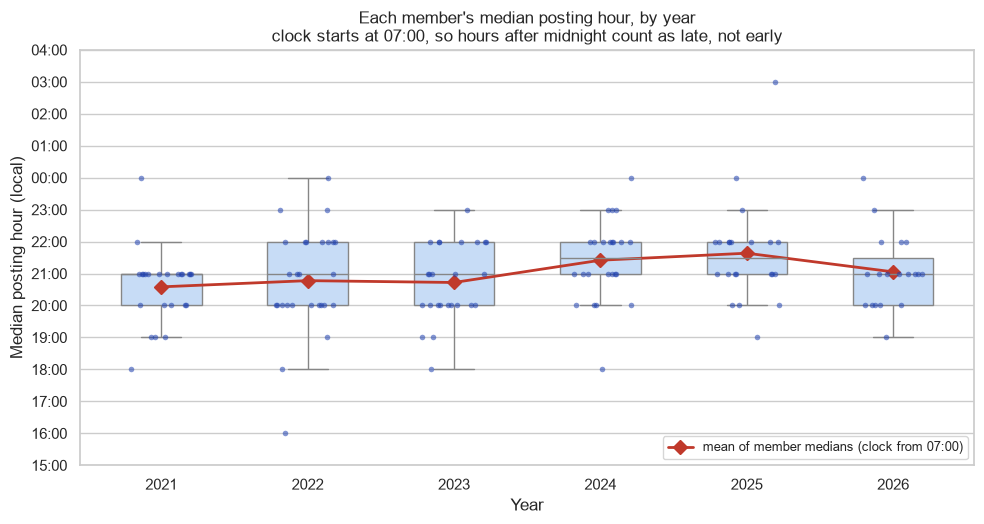

year    wrapped     plain mean    from-07:00 mean
2021          1          19.58              20.58
2022          1          19.89              20.78
2023          0          20.72              20.72
2024          1          20.42              21.42
2025          2          19.45              21.64
2026          1          19.79              21.05

Drift 2021 -> 2025: +1.05 hours (later; the prediction was earlier)


In [5]:
mh = real_years(member_hr).copy()
mh["rot"] = to_rot(mh["median_hour_local"])

fig, ax = plt.subplots(figsize=(10, 5.4))
sns.boxplot(data=mh, x="year", y="rot", ax=ax, color="#bfdbfe", fliersize=0, width=0.55)
sns.stripplot(data=mh, x="year", y="rot", ax=ax, color="#1e40af", alpha=0.55,
              size=4, jitter=0.22)

rot_mean = mh.groupby("year")["rot"].mean()
ax.plot(range(len(rot_mean)), rot_mean.values, color="#c0392b", marker="D",
        markersize=7, linewidth=2, label="mean of member medians (clock from 07:00)")

ticks = np.arange(int(mh["rot"].min()) - 1, int(mh["rot"].max()) + 2)
ax.set_yticks(ticks)
ax.set_yticklabels([f"{int(from_rot(t)):02d}:00" for t in ticks])
ax.set_title("Each member's median posting hour, by year\n"
             "clock starts at 07:00, so hours after midnight count as late, not early",
             fontsize=12)
ax.set_xlabel("Year")
ax.set_ylabel("Median posting hour (local)")
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "11_member_median_hour.png"), dpi=150)
plt.show()

real_mean = from_rot(rot_mean)
naive = mh.groupby("year")["median_hour_local"].mean()
print(f"{'year':<6}{'wrapped':>9}{'plain mean':>15}{'from-07:00 mean':>19}")
for y in rot_mean.index:
    n_wrap = int((mh[mh['year'] == y]['median_hour_local'] < DAY_START).sum())
    print(f"{y:<6}{n_wrap:>9}{naive[y]:>15.2f}{real_mean[y]:>19.2f}")
drift = real_mean.loc[2025] - real_mean.loc[2021]
print(f"\nDrift 2021 -> 2025: {drift:+.2f} hours (later; the prediction was earlier)")

### Same members, compared with themselves

Only members present in both years, each compared with their own earlier hour, so changes in who
is present can't affect the result.

In [6]:
pv = mh.pivot(index="pseudonym", columns="year", values="rot")
rows = []
for a, b in [(2021, 2025), (2022, 2025), (2022, 2024), (2022, 2026), (2021, 2026)]:
    pair = pv[[a, b]].dropna()
    d = pair[b] - pair[a]
    rows.append({"from": a, "to": b, "n": len(pair),
                 "median_shift_h": round(d.median(), 2),
                 "mean_shift_h": round(d.mean(), 2),
                 "later": int((d > 0).sum()),
                 "earlier": int((d < 0).sum()),
                 "unchanged": int((d == 0).sum())})
paired = pd.DataFrame(rows)
print(paired.to_string(index=False))
print()

 from   to  n  median_shift_h  mean_shift_h  later  earlier  unchanged
 2021 2025 18             1.0          1.00     11        2          5
 2022 2025 20             0.0          0.85      9        3          8
 2022 2024 22             0.0          0.55     10        0         12
 2022 2026 17             0.0          0.18      6        7          4
 2021 2026 15             0.0          0.20      4        4          7



## 2. Weekends

Weekend share didn't rise. Year by year, the weekend premium (weekend messages per day ÷ weekday
messages per day) seems to appear in 2022–24 and disappear in 2025–26. Quarter by quarter (21
quarters), it moves with neither volume nor time. The correlation (from −1 to +1, where 0 means
no relationship) is:

- with volume per day (on a log scale, so a doubling counts the same at any level): **+0.06**
- with time: **−0.05**

The quarterly values run from 0.81 to 1.71, with a standard deviation (the typical distance from
the average) of 0.24, so the yearly change is within normal quarter-to-quarter variation. A
t-test comparing 2021–24 with 2025–26 gives p ≈ 0.15: a difference that size would often turn up
by chance. With only 21 quarters a small effect could still be missed, so the result is that no
weekend effect is detectable, not that there is none.

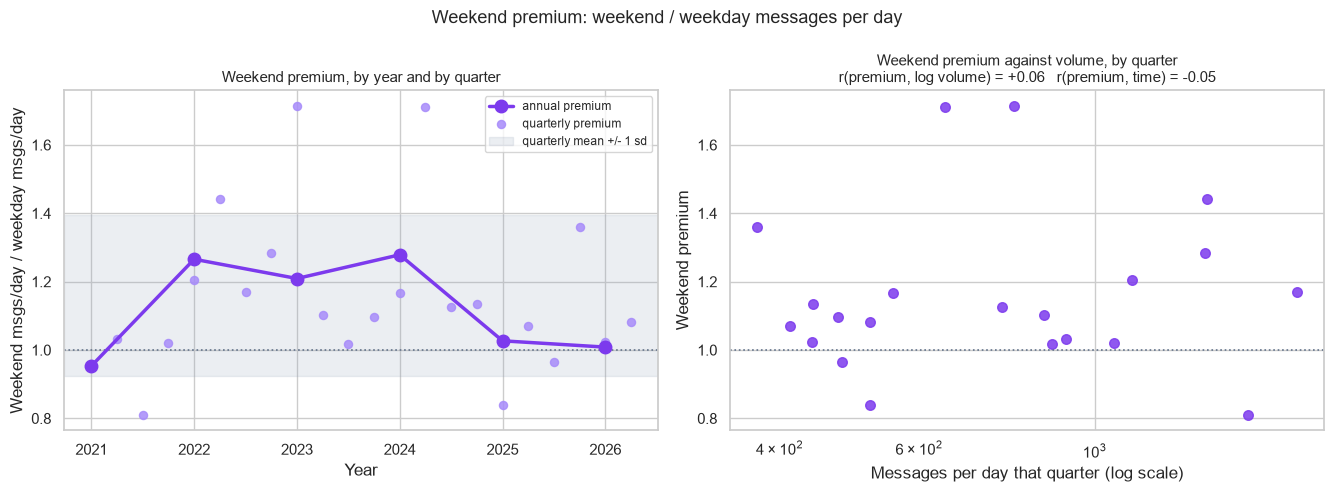

quarterly premium: mean 1.161, sd 0.236, range 0.81-1.71
2021-2024 (n=15): 1.202   2025-2026 (n=6): 1.056
Welch t = 1.53, p = 0.149  -> not significant


In [7]:
w = real_years(weekend).copy()
w["premium"] = w["weekend_msgs_per_day"] / w["weekday_msgs_per_day"]
q = wk_quarter.copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5))

ax1.plot(w["year"], w["premium"], marker="o", markersize=9, linewidth=2.5,
         color="#7c3aed", label="annual premium", zorder=3)
ax1.scatter(q["time_index"], q["weekend_premium"], color="#a78bfa", s=34,
            alpha=0.85, label="quarterly premium", zorder=2)
ax1.axhline(1.0, color="#64748b", linestyle=":", linewidth=1.2)
ax1.axhspan(q["weekend_premium"].mean() - q["weekend_premium"].std(),
            q["weekend_premium"].mean() + q["weekend_premium"].std(),
            color="#94a3b8", alpha=0.18, label="quarterly mean +/- 1 sd")
ax1.set_xlabel("Year")
ax1.set_ylabel("Weekend msgs/day / weekday msgs/day")
ax1.set_title("Weekend premium, by year and by quarter", fontsize=11)
ax1.legend(fontsize=8.5)

ax2.scatter(q["messages_per_day"], q["weekend_premium"], s=48, color="#7c3aed", alpha=0.85)
ax2.set_xscale("log")
ax2.axhline(1.0, color="#64748b", linestyle=":", linewidth=1.2)
r_vol = np.corrcoef(q["weekend_premium"], np.log(q["messages_per_day"]))[0, 1]
r_time = np.corrcoef(q["weekend_premium"], q["time_index"])[0, 1]
ax2.set_xlabel("Messages per day that quarter (log scale)")
ax2.set_ylabel("Weekend premium")
ax2.set_title(f"Weekend premium against volume, by quarter\n"
              f"r(premium, log volume) = {r_vol:+.2f}   r(premium, time) = {r_time:+.2f}",
              fontsize=11)

fig.suptitle("Weekend premium: weekend / weekday messages per day",
             fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "12_weekend_premium.png"), dpi=150)
plt.show()

pre, post = q[q["year"] <= 2024]["weekend_premium"], q[q["year"] >= 2025]["weekend_premium"]
t = stats.ttest_ind(pre, post, equal_var=False)
print(f"quarterly premium: mean {q['weekend_premium'].mean():.3f}, sd {q['weekend_premium'].std():.3f}, "
      f"range {q['weekend_premium'].min():.2f}-{q['weekend_premium'].max():.2f}")
print(f"2021-2024 (n={len(pre)}): {pre.mean():.3f}   2025-2026 (n={len(post)}): {post.mean():.3f}")
print(f"Welch t = {t.statistic:.2f}, p = {t.pvalue:.3f}  -> not significant")

## 3. Seasonality

The summer premium shrinks, which is what the student-calendar story predicts. But:

- **Summer is also when the tournaments are** (about 1.5× for a month, Step 2), and 2024 breaks
  the trend because of Euro 2024. This measure can't separate the two calendars.
- **2021 and 2026 aren't comparable.** In early 2021 the server was barely active (January 0.00,
  February 0.02, March 0.19, April 0.13), which inflates the other months; 2026 covers only
  January–August. Both are greyed out and excluded from the trend.

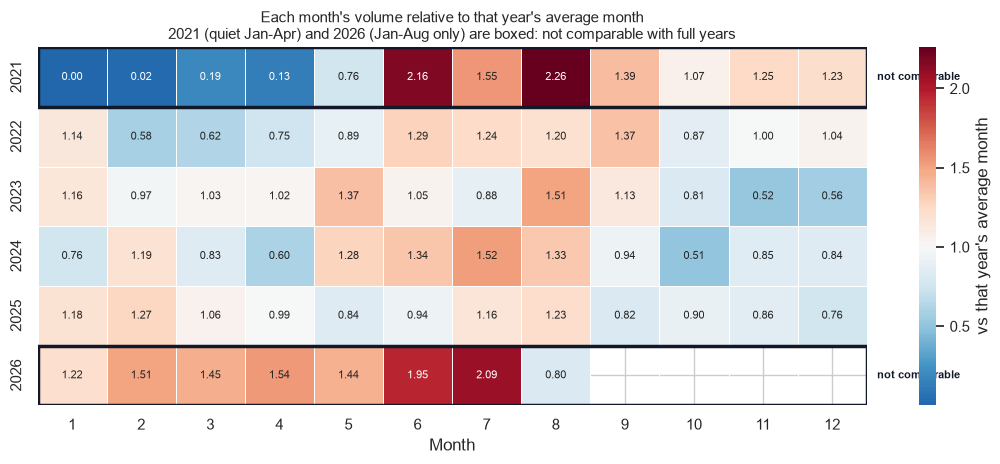

Summer (Jun-Aug) vs rest, comparable years only:
  2022: summer 1.24  rest 0.92  premium 1.36x
  2023: summer 1.15  rest 0.95  premium 1.21x
  2024: summer 1.40  rest 0.87  premium 1.61x   <- Euro 2024
  2025: summer 1.11  rest 0.96  premium 1.15x


In [8]:
s = real_years(seasonal).copy()
s["rel"] = s["share_of_year_rate"] * 12
piv = s.pivot(index="year", columns="month", values="rel")

NOT_COMPARABLE = [2021, PARTIAL_YEAR]
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(piv, cmap="RdBu_r", center=1.0, ax=ax, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, linewidths=0.4, linecolor="white",
            cbar_kws={"label": "vs that year's average month"})
for i, y in enumerate(piv.index):
    if y in NOT_COMPARABLE:
        ax.add_patch(plt.Rectangle((0, i), piv.shape[1], 1, fill=False,
                                   edgecolor="#111827", linewidth=2.5, zorder=5))
        ax.text(piv.shape[1] + 0.15, i + 0.5, "not comparable", va="center",
                fontsize=8, color="#111827", weight="bold")
ax.set_title("Each month's volume relative to that year's average month\n"
             "2021 (quiet Jan-Apr) and 2026 (Jan-Aug only) are boxed: "
             "not comparable with full years", fontsize=11)
ax.set_xlabel("Month")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "13_seasonality_heatmap.png"), dpi=150)
plt.show()

comp = s[~s["year"].isin(NOT_COMPARABLE)]
summer = comp[comp["month"].isin([6, 7, 8])].groupby("year")["rel"].mean()
rest = comp[~comp["month"].isin([6, 7, 8])].groupby("year")["rel"].mean()
print("Summer (Jun-Aug) vs rest, comparable years only:")
for y in summer.index:
    star = "   <- Euro 2024" if y == 2024 else ""
    print(f"  {y}: summer {summer[y]:.2f}  rest {rest[y]:.2f}  premium {summer[y]/rest[y]:.2f}x{star}")

## 4. Reply speed

The median reply time goes from 42s (2022) to 131s (2025), ×3.1. On its own that says little,
because a quieter room produces slower replies by itself.

Dividing by the median gap between messages assumes reply time scales with room speed, and the
result depends heavily on the chosen years:

| years | change |
|---|---|
| 2022 → 2025 | ×1.55 |
| 2021 → 2025 | ×1.29 |
| 2021 → 2026 | ×1.14 |

A better measure is **how many messages were posted between a message and its reply**. It
doesn't depend on how busy the room is: "three messages went by" means the same in a busy room
and a quiet one.

On that measure, reply distance is **flat from 2022 on**: a median of 3 messages in every year
from 2022 to 2026 (4 in 2021), with 65–69% of replies arriving within 5 messages.

Counted in messages, the rhythm of conversation didn't change. This can't say why replies got
slower in seconds: fewer messages arriving and slower individual replies both stretch time in the
same way. It also only covers explicit replies, and pools whoever was posting each year.

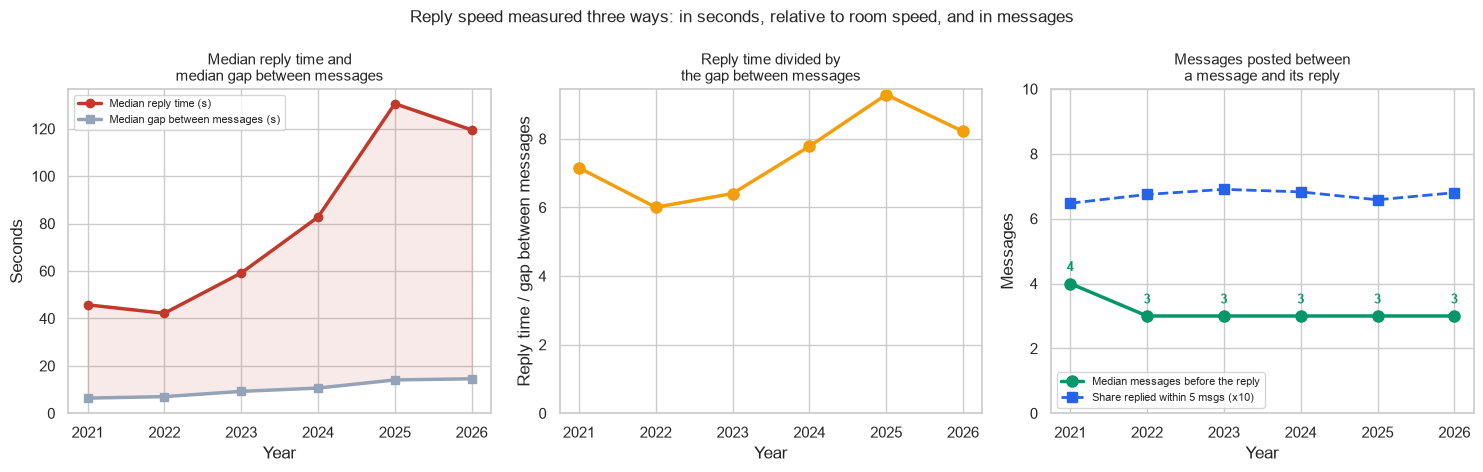

Reply time / gap, depending on which years are compared:
  2022 -> 2025:  6.01 -> 9.29   x1.55
  2021 -> 2025:  7.15 -> 9.29   x1.30
  2021 -> 2026:  7.15 -> 8.22   x1.15

Messages posted between a message and its reply:
 year  reply_pairs  median_interposed  share_replied_immediately  share_within_5_messages
 2021        24352                4.0                      0.050                    0.648
 2022        63670                3.0                      0.050                    0.675
 2023        32638                3.0                      0.063                    0.690
 2024        29005                3.0                      0.064                    0.683
 2025        23867                3.0                      0.052                    0.658
 2026        17460                3.0                      0.064                    0.680


In [9]:
l = real_years(latency).copy()
i = real_years(interposed).copy()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.8))

ax1.plot(l["year"], l["median_reply_latency_sec"], marker="o", linewidth=2.5,
         color="#c0392b", label="Median reply time (s)")
ax1.plot(l["year"], l["median_gap_sec"], marker="s", linewidth=2.5,
         color="#94a3b8", label="Median gap between messages (s)")
ax1.fill_between(l["year"], l["median_gap_sec"], l["median_reply_latency_sec"],
                 color="#c0392b", alpha=0.10)
ax1.set_ylabel("Seconds"); ax1.set_xlabel("Year"); ax1.set_ylim(bottom=0)
ax1.set_title("Median reply time and\nmedian gap between messages", fontsize=10.5)
ax1.legend(fontsize=8)

ax2.plot(l["year"], l["latency_to_gap_ratio"], marker="o", markersize=8,
         linewidth=2.5, color="#f59e0b")
ax2.set_ylabel("Reply time / gap between messages"); ax2.set_xlabel("Year")
ax2.set_ylim(bottom=0)
ax2.set_title("Reply time divided by\nthe gap between messages", fontsize=10.5)

ax3.plot(i["year"], i["median_interposed"], marker="o", markersize=8,
         linewidth=2.5, color="#059669", label="Median messages before the reply")
ax3.plot(i["year"], i["share_within_5_messages"] * 10, marker="s", markersize=7,
         linewidth=2, color="#2563eb", linestyle="--",
         label="Share replied within 5 msgs (x10)")
for _, r in i.iterrows():
    ax3.annotate(f"{r.median_interposed:.0f}", (r.year, r.median_interposed),
                 textcoords="offset points", xytext=(0, 9), ha="center",
                 fontsize=9, weight="bold", color="#059669")
ax3.set_ylabel("Messages"); ax3.set_xlabel("Year"); ax3.set_ylim(0, 10)
ax3.set_title("Messages posted between\na message and its reply", fontsize=10.5)
ax3.legend(fontsize=8, loc="lower left")

fig.suptitle("Reply speed measured three ways: in seconds, relative to room speed, and in messages",
             fontsize=12.5)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "14_reply_latency_controlled.png"), dpi=150)
plt.show()

print("Reply time / gap, depending on which years are compared:")
for a, b in [(2022, 2025), (2021, 2025), (2021, 2026)]:
    ra = l[l["year"] == a]["latency_to_gap_ratio"].iloc[0]
    rb = l[l["year"] == b]["latency_to_gap_ratio"].iloc[0]
    print(f"  {a} -> {b}:  {ra:.2f} -> {rb:.2f}   x{rb/ra:.2f}")
print()
print("Messages posted between a message and its reply:")
print(i[["year", "reply_pairs", "median_interposed", "share_replied_immediately",
         "share_within_5_messages"]].round(3).to_string(index=False))

## 5. What did change: more explicit replies

| | 2021 | 2022 | 2023 | 2024 | 2025 | 2026 |
|---|---|---|---|---|---|---|
| share of messages that are explicit replies | 7.5% | 12.5% | 12.0% | 13.3% | 14.7% | **16.0%** |

Discord added inline replies in [the week of 17 November
2020](https://www.xda-developers.com/discord-rolling-out-inline-replies-desktop-mobile/), while
this server was inactive (2020-11-29 → 2021-01-29). The first reply in the archive is from
2021-03-11, and the monthly share then climbs smoothly while the group picks up the habit:

`3.1% (Mar) → 6.0% (Jun) → 8.5% (Sep) → 10.2% (Dec) → 11.1% (Jan 22) → plateau`

So 2021 is a period of uptake, and the comparison starts in 2022: **12.5% → 16.0%**, about 28%
higher, with one dip in 2023.

A possible explanation: in a quiet room you have to point at what you're answering. That would
mean higher reply share when volume is lower. On 56 monthly points from 2022 on:

| | |
|---|---|
| r(reply share, time) | **+0.80** |
| r(reply share, log volume) | −0.49 |
| r(log volume, time) | −0.78 |
| **partial r(reply share, log volume, controlling for time)** | **+0.37** |

(r is the correlation.) Volume and time move together, so the raw −0.49 can't separate them. A
partial correlation measures the link between two things after removing what each shares with a
third, here time. Controlling for time this way, busier months have a higher reply share, the opposite of what that explanation predicts. Tournament
months, which are much busier, don't show a lower reply share either.

So this is a real change over time, not a side effect of volume. Its cause isn't identified.
Possible explanations: the habit growing, fewer simultaneous conversations, or a change in who
talks to whom (tested in Step 4).

Because reply share rises, any comparison of reply networks between periods is made per message,
not per unit of time.

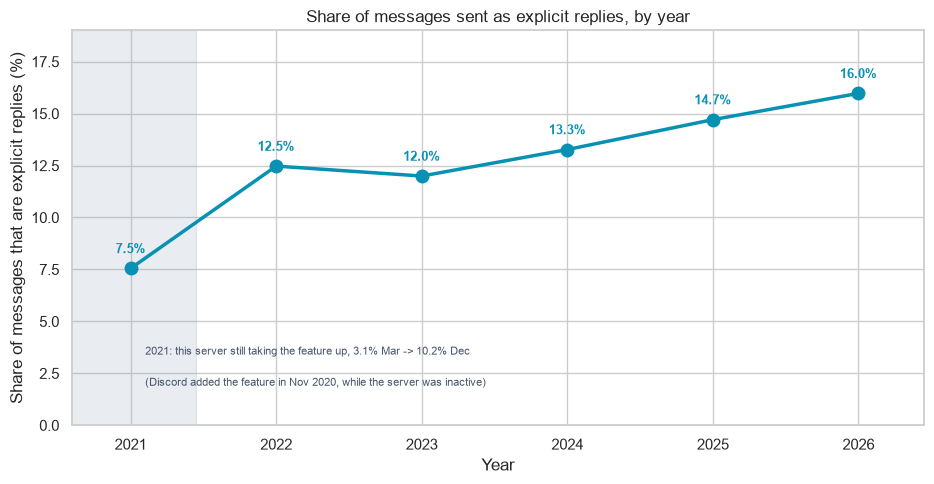

2022 -> 2026 (post-uptake): 12.5% -> 16.0%   relative +28%

Volume-vs-time control, 56 monthly points from 2022:
  r(share, time)       = +0.802
  r(share, log volume) = -0.486
  r(log volume, time)  = -0.780
  partial r(share, log volume | time) = +0.374

Tournament months (high volume) against the year's reply share:
  World Cup 2022  2022-12    1478/day  share 13.3%  vs year 12.5%
  Euro 2024       2024-06     809/day  share 13.8%  vs year 13.3%
  World Cup 2026  2026-06     618/day  share 15.4%  vs year 16.0%

2021 reply share by month:
  2021-03   3.1%
  2021-04   3.7%
  2021-05   5.5%
  2021-06   6.0%
  2021-07   7.2%
  2021-08   6.8%
  2021-09   8.5%
  2021-10   8.8%
  2021-11   9.2%
  2021-12  10.2%

Median posting hour by month, 2021-2025:
 month  messages  median_hour_local
     1    107569               21.0
     2     79991               21.0
     3     82987               21.0
     4     82351               20.0
     5    127838               21.0
     6    173494         

In [10]:
rs = real_years(reply_share)

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(rs["year"], rs["reply_share"] * 100, marker="o", markersize=9,
        linewidth=2.5, color="#0891b2")
for _, r in rs.iterrows():
    ax.annotate(f"{r.reply_share:.1%}", (r.year, r.reply_share * 100),
                textcoords="offset points", xytext=(0, 11), ha="center",
                fontsize=9, weight="bold", color="#0891b2")
ax.axvspan(2020.55, 2021.45, color="#94a3b8", alpha=0.20)
ax.set_xlim(2020.6, 2026.45)
ax.annotate("2021: this server still taking the feature up, 3.1% Mar -> 10.2% Dec",
            (2021.1, 3.4), ha="left", fontsize=8, color="#475569")
ax.annotate("(Discord added the feature in Nov 2020, while the server was inactive)",
            (2021.1, 1.9), ha="left", fontsize=8, color="#475569")
ax.set_ylim(0, 19)
ax.set_xlabel("Year")
ax.set_ylabel("Share of messages that are explicit replies (%)")
ax.set_title("Share of messages sent as explicit replies, by year",
             fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "15_reply_share.png"), dpi=150)
plt.show()

a = rs[rs["year"] == 2022]["reply_share"].iloc[0]
b = rs[rs["year"] == 2026]["reply_share"].iloc[0]
print(f"2022 -> 2026 (post-uptake): {a:.1%} -> {b:.1%}   relative +{b / a - 1:.0%}")
print()
rm = reply_month.copy()
rm["year"] = rm["month"].str[:4].astype(int)
rm["mo"] = rm["month"].str[5:].astype(int)
rm["t"] = rm["year"] + (rm["mo"] - 1) / 12
vol = seasonal[["year", "month", "messages_per_day"]].rename(columns={"month": "mo"})
rm = rm.merge(vol, on=["year", "mo"], how="inner")
rm = rm[rm["year"] >= 2022]

xs, zs = rm["reply_share"].values, rm["t"].values
ys = np.log(rm["messages_per_day"].values)
rxy = np.corrcoef(xs, ys)[0, 1]
rxz = np.corrcoef(xs, zs)[0, 1]
ryz = np.corrcoef(ys, zs)[0, 1]
partial = (rxy - rxz * ryz) / np.sqrt((1 - rxz ** 2) * (1 - ryz ** 2))
print(f"Volume-vs-time control, {len(rm)} monthly points from 2022:")
print(f"  r(share, time)       = {rxz:+.3f}")
print(f"  r(share, log volume) = {rxy:+.3f}")
print(f"  r(log volume, time)  = {ryz:+.3f}")
print(f"  partial r(share, log volume | time) = {partial:+.3f}")
print()
print("Tournament months (high volume) against the year's reply share:")
ann = reply_share.set_index("year")["reply_share"]
for lbl, yy, mm in [("World Cup 2022", 2022, 12), ("Euro 2024", 2024, 6),
                    ("World Cup 2026", 2026, 6)]:
    row = rm[(rm["year"] == yy) & (rm["mo"] == mm)].iloc[0]
    print(f"  {lbl:<15} {row.month}  {row.messages_per_day:>6.0f}/day  "
          f"share {row.reply_share:5.1%}  vs year {ann[yy]:5.1%}")
print()
print("2021 reply share by month:")
r21 = reply_month[reply_month["month"].str.startswith("2021")]
for _, r in r21.iterrows():
    print(f"  {r.month}  {r.reply_share:5.1%}")
print()
print("Median posting hour by month, 2021-2025:")
print(hour_month.to_string(index=False))
print()

In [11]:
myr = pd.read_csv(os.path.join(TABLES_DIR, "member_year_replies.csv"))

def reply_split(y0, y1):
    a = myr[myr["year"] == y0].set_index("pseudonym")
    b = myr[myr["year"] == y1].set_index("pseudonym")
    both = a.index.intersection(b.index)
    s0, s1 = a["messages"] / a["messages"].sum(), b["messages"] / b["messages"].sum()
    r0, r1 = a["replies"] / a["messages"], b["replies"] / b["messages"]
    total = b["replies"].sum() / b["messages"].sum() - a["replies"].sum() / a["messages"].sum()
    within = ((s0[both] + s1[both]) / 2 * (r1[both] - r0[both])).sum()
    return total, within

print("Reply share change: within members vs composition (members in only one year count as composition):")
for y0, y1, note in [(2022, 2025, "full years"), (2022, 2026, "2026 partial")]:
    t, w = reply_split(y0, y1)
    print(f"  {y0} -> {y1} ({note}): {t * 100:+.2f} pts = within members {w * 100:+.2f}, "
          f"composition {(t - w) * 100:+.2f}  ({w / t:.0%} within)")

Reply share change: within members vs composition (members in only one year count as composition):
  2022 -> 2025 (full years): +2.24 pts = within members +2.29, composition -0.05  (102% within)
  2022 -> 2026 (2026 partial): +3.50 pts = within members +3.01, composition +0.49  (86% within)


## Summary

None of the four tests supports the student-to-work explanation: two show no predicted change or
the opposite one, seasonality is inconclusive, and the reply-speed change disappears when
measured in messages.

| | |
|---|---|
| Busiest hour | 23:00 in all six years |
| Members' median hour, averaged | about 1 hour **later**, 20:35 → 21:38 (2021 → 2025) |
| Weekend effect | none detectable |
| Reply distance | unchanged in messages, a median of 3, 2022–2026 |
| Explicit reply share | **rose 12.5% → 16.0%** (2022 → 2026), mostly the same people replying more |
| Message length | **rose ~30 → ~43 characters** (2022 → 2025; Step 1), mostly within members |
| Volume | down ~69% |

Most of how the community uses the server didn't change: the same hours, the same pace, no
weekly rhythm gained or lost. Two things did change: more messages are explicit replies, and
messages got longer (Step 1). Both are mostly the same people changing, not a change in who is
left. Why individuals changed how they write isn't identified here.

**Limitations:**
- Seasonality can't separate the academic calendar from the football calendar.
- One reference time zone for members in several countries: fine for drift, not for absolute
  hours.
- Reply measures only see messages sent with the Reply button, not conversation in general.
- The drift to later hours is about 1 hour over 2021–2025, among roughly two thirds of the
  members present in both years, and gone by 2026.
- Reply share before 2022 reflects the group picking up the habit, so only 2022 → 2026 counts as
  a change in behaviour.